Initializing NUTS using jitter+adapt_diag...
Multiprocess sampling (2 chains in 2 jobs)
NUTS: [Y]
Sampling 2 chains for 1_000 tune and 1_000 draw iterations (2_000 + 2_000 draws total) took 8 seconds.
We recommend running at least 4 chains for robust computation of convergence diagnostics


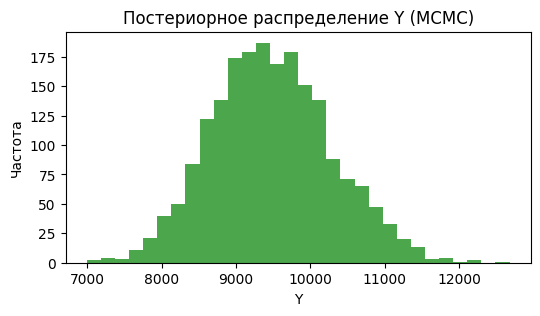

Истинное Y: 10000
Среднее из MCMC: 9480


In [2]:
import numpy as np
import pymc as pm
import matplotlib.pyplot as plt

class Detector:
    def __init__(self, R, r, N):
        self.R = R
        self.r = r
        self.N = N
        self.positions = self._place_pmt()

    def _place_pmt(self):
        points = []
        while len(points) < self.N:
            p = np.random.uniform(-1, 1, size=3)
            length = np.linalg.norm(p)
            if 0 < length <= 1:
                points.append(p / length * self.R)
        return np.array(points)

det = Detector(R=2.0, r=0.1, N=40)

Y_true = 10000
E = 1.0
a = 0.5
N_photons = int(E * Y_true)

phi = np.random.uniform(0, 2 * np.pi, N_photons)
cos_theta = np.random.uniform(-1, 1, N_photons)
sin_theta = np.sqrt(1 - cos_theta**2)
dirs = np.column_stack((sin_theta * np.cos(phi), sin_theta * np.sin(phi), cos_theta))
hit_points = dirs * det.R

L_abs = 10.0
dist_to_wall = np.random.exponential(L_abs, N_photons)
survived_mask = dist_to_wall > det.R
hit_points = hit_points[survived_mask]

dists = np.linalg.norm(hit_points[:, np.newaxis, :] - det.positions[np.newaxis, :, :], axis=2)
hits = np.sum(dists <= det.r, axis=0)
observed_Q = np.sum(np.random.poisson(a * hits))

with pm.Model() as model:
    Y = pm.HalfNormal('Y', sigma=2000)
    mu = a * E * Y * (det.N * det.r**2) / (4 * det.R**2) * np.exp(-det.R / L_abs)
    Q = pm.Poisson('Q', mu=mu, observed=observed_Q)
    
    trace = pm.sample(1000, tune=1000, chains=2, progressbar=False)

plt.figure(figsize=(6, 3))
plt.hist(trace.posterior['Y'].values.flatten(), bins=30, color='green', alpha=0.7)
plt.xlabel('Y')
plt.ylabel('Частота')
plt.title('Постериорное распределение Y (MCMC)')
plt.show()

print(f"Истинное Y: {Y_true}")
print(f"Среднее из MCMC: {np.mean(trace.posterior['Y'].values):.0f}")